In [1]:

!nvidia-smi

!git clone https://github.com/karpathy/nanoGPT.git
%cd /content/nanoGPT

!pip install -q tiktoken


Mon Nov  9 00:50:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

# Step 2: Prepare Shakespeare dataset

%cd /content/nanoGPT

!python data/shakespeare_char/prepare.py

# Verify dataset files
import os

dataset_path = "data/shakespeare_char"

print("\nDataset files:")
print(os.listdir(dataset_path))

print("\nTraining data prepared successfully!")


/content/nanoGPT
length of dataset in characters: 1,115,394
all the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
vocab size: 65
train has 1,003,854 tokens
val has 111,540 tokens

Dataset files:
['train.bin', 'meta.pkl', 'prepare.py', 'readme.md', 'input.txt', 'val.bin']

Training data prepared successfully!


In [3]:

# Step 3: Member 3 - Experiment 1

%cd /content/nanoGPT

!python train.py \
    --dataset=shakespeare_char \
    --device=cuda \
    --dtype=float16 \
    --compile=False \
    --block_size=128 \
    --n_layer=4 \
    --n_head=4 \
    --n_embd=128 \
    --batch_size=8 \
    --max_iters=1000 \
    --dropout=0.1 \
    --learning_rate=1e-3 \
    --gradient_accumulation_steps=1 \
    --eval_interval=100 \
    --eval_iters=20 \
    --log_interval=10 \
    --always_save_checkpoint=True \
    --seed=1337 \
    --out_dir=out-member3-exp1


/content/nanoGPT
Overriding: dataset = shakespeare_char
Overriding: device = cuda
Overriding: dtype = float16
Overriding: compile = False
Overriding: block_size = 128
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: batch_size = 8
Overriding: max_iters = 1000
Overriding: dropout = 0.1
Overriding: learning_rate = 0.001
Overriding: gradient_accumulation_steps = 1
Overriding: eval_interval = 100
Overriding: eval_iters = 20
Overriding: log_interval = 10
Overriding: always_save_checkpoint = True
Traceback (most recent call last):
  File "/content/nanoGPT/train.py", line 77, in <module>
    exec(open('configurator.py').read()) # overrides from command line or config file
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<string>", line 47, in <module>
ValueError: Unknown config key: seed


In [4]:

# Member 3 - Experiment 1 (Corrected)

%cd /content/nanoGPT

!python train.py \
    --dataset=shakespeare_char \
    --device=cuda \
    --dtype=float16 \
    --compile=False \
    --block_size=128 \
    --n_layer=4 \
    --n_head=4 \
    --n_embd=128 \
    --batch_size=8 \
    --max_iters=1000 \
    --dropout=0.1 \
    --learning_rate=1e-3 \
    --gradient_accumulation_steps=1 \
    --eval_interval=100 \
    --eval_iters=20 \
    --log_interval=10 \
    --always_save_checkpoint=True \
    --out_dir=out-member3-exp1


/content/nanoGPT
Overriding: dataset = shakespeare_char
Overriding: device = cuda
Overriding: dtype = float16
Overriding: compile = False
Overriding: block_size = 128
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: batch_size = 8
Overriding: max_iters = 1000
Overriding: dropout = 0.1
Overriding: learning_rate = 0.001
Overriding: gradient_accumulation_steps = 1
Overriding: eval_interval = 100
Overriding: eval_iters = 20
Overriding: log_interval = 10
Overriding: always_save_checkpoint = True
Overriding: out_dir = out-member3-exp1
tokens per iteration will be: 1,024
found vocab_size = 65 (inside data/shakespeare_char/meta.pkl)
Initializing a new model from scratch
number of parameters: 0.80M
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))
num decayed parameter tensors: 18, with 8

In [5]:

# Step 5: Save Experiment 1 checkpoint to Google Drive

from google.colab import drive
import os
import shutil

drive.mount('/content/drive')

source = '/content/nanoGPT/out-member3-exp1'
destination = '/content/drive/MyDrive/nanoGPT_Experiments/Member3/Experiment1'

os.makedirs(destination, exist_ok=True)

shutil.copy2(
    os.path.join(source, 'ckpt.pt'),
    os.path.join(destination, 'ckpt.pt')
)

print("Experiment 1 checkpoint saved successfully!")
print("Saved to:", destination)


Mounted at /content/drive
Experiment 1 checkpoint saved successfully!
Saved to: /content/drive/MyDrive/nanoGPT_Experiments/Member3/Experiment1


In [6]:

import os
import csv
import itertools

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
os.makedirs(base_dir, exist_ok=True)

results_file = os.path.join(base_dir, "experiment_results.csv")

fields = [
    "member", "experiment", "block_size",
    "n_layer", "n_head", "n_embd",
    "batch_size", "max_iters", "dropout",
    "train_loss", "val_loss", "training_time_sec",
    "status"
]

if not os.path.exists(results_file):
    with open(results_file, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()

# Generate all combinations
experiments = []

for member, n_layer in [(3, 4), (4, 6)]:
    combinations = itertools.product(
        [4, 8],       # n_head
        [128, 256],   # n_embd
        [8, 16],      # batch_size
        [1000, 2000], # max_iters
        [0.1, 0.2]    # dropout
    )

    for exp_num, (head, embd, batch, iters, drop) in enumerate(combinations, 1):
        experiments.append({
            "member": member,
            "experiment": exp_num,
            "block_size": 128,
            "n_layer": n_layer,
            "n_head": head,
            "n_embd": embd,
            "batch_size": batch,
            "max_iters": iters,
            "dropout": drop
        })

print("Total experiments:", len(experiments))
print("Member 3:", sum(e["member"] == 3 for e in experiments))
print("Member 4:", sum(e["member"] == 4 for e in experiments))
print("Results file:", results_file)


Total experiments: 64
Member 3: 32
Member 4: 32
Results file: /content/drive/MyDrive/nanoGPT_Experiments/experiment_results.csv


In [7]:

# Record the completed first experiment

import csv
import os

completed = {
    "member": 3,
    "experiment": 1,
    "block_size": 128,
    "n_layer": 4,
    "n_head": 4,
    "n_embd": 128,
    "batch_size": 8,
    "max_iters": 1000,
    "dropout": 0.1,
    "train_loss": 2.3992,
    "val_loss": 2.4216,
    "training_time_sec": "",
    "status": "completed"
}

with open(results_file, newline="") as f:
    existing = list(csv.DictReader(f))

if not any(
    int(r["member"]) == 3 and
    int(r["experiment"]) == 1 and
    r["status"] == "completed"
    for r in existing
):
    with open(results_file, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writerow(completed)

print("Experiment 1 recorded successfully!")
print("Completed: 1 / 64")


Experiment 1 recorded successfully!
Completed: 1 / 64


In [8]:

# Step 8: Automatic nanoGPT experiment runner

import os
import csv
import time
import re
import subprocess
import shutil

project_dir = "/content/nanoGPT"
base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"

def run_experiment(exp):
    member = exp["member"]
    number = exp["experiment"]

    name = f"member{member}-exp{number}"
    local_dir = os.path.join(project_dir, "runs", name)
    drive_dir = os.path.join(
        base_dir, f"Member{member}", f"Experiment{number}"
    )

    os.makedirs(local_dir, exist_ok=True)
    os.makedirs(drive_dir, exist_ok=True)

    command = [
        "python", "-u", "train.py",
        "--dataset=shakespeare_char",
        "--device=cuda",
        "--dtype=float16",
        "--compile=False",
        f"--block_size={exp['block_size']}",
        f"--n_layer={exp['n_layer']}",
        f"--n_head={exp['n_head']}",
        f"--n_embd={exp['n_embd']}",
        f"--batch_size={exp['batch_size']}",
        f"--max_iters={exp['max_iters']}",
        f"--dropout={exp['dropout']}",
        "--learning_rate=1e-3",
        "--gradient_accumulation_steps=1",
        "--eval_interval=100",
        "--eval_iters=20",
        "--log_interval=10",
        "--always_save_checkpoint=True",
        f"--out_dir={local_dir}"
    ]

    print(f"\nStarting {name}", flush=True)
    start = time.perf_counter()
    output_lines = []

    log_path = os.path.join(drive_dir, "training.log")

    with open(log_path, "w") as log:
        process = subprocess.Popen(
            command,
            cwd=project_dir,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1
        )

        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
            output_lines.append(line)

        return_code = process.wait()

    elapsed = time.perf_counter() - start

    if return_code != 0:
        print(f"Training failed for {name}")
        return False

    # Extract final evaluated train/validation losses
    pattern = re.compile(
        r"step\s+(\d+): train loss\s+([\d.]+), "
        r"val loss\s+([\d.]+)"
    )

    matches = []
    for line in output_lines:
        match = pattern.search(line)
        if match:
            matches.append(match)

    if not matches:
        print("No evaluation results found.")
        return False

    final = matches[-1]
    final_step = int(final.group(1))

    if final_step < exp["max_iters"]:
        print("Final evaluation was not reached.")
        return False

    train_loss = float(final.group(2))
    val_loss = float(final.group(3))

    # Save checkpoint to Drive
    checkpoint = os.path.join(local_dir, "ckpt.pt")
    if not os.path.isfile(checkpoint):
        print("Checkpoint missing. Experiment not recorded.")
        return False

    shutil.copy2(
        checkpoint,
        os.path.join(drive_dir, "ckpt.pt")
    )

    # Save evaluation history
    history_path = os.path.join(drive_dir, "loss_history.csv")

    with open(history_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["step", "train_loss", "val_loss"])
        for match in matches:
            writer.writerow([
                int(match.group(1)),
                float(match.group(2)),
                float(match.group(3))
            ])

    # Record experiment results
    row = {
        **exp,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "training_time_sec": round(elapsed, 2),
        "status": "completed"
    }

    with open(results_file, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writerow(row)

    print(f"\n{name} completed successfully!")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Wall-clock time: {elapsed:.2f} seconds")
    print(f"Saved to: {drive_dir}")

    return True


In [9]:

# Test the automatic runner on Member 3, Experiment 2

experiment_2 = next(
    e for e in experiments
    if e["member"] == 3 and e["experiment"] == 2
)

print("Experiment configuration:")
print(experiment_2)

success = run_experiment(experiment_2)

print("\nExperiment 2 success:", success)


Experiment configuration:
{'member': 3, 'experiment': 2, 'block_size': 128, 'n_layer': 4, 'n_head': 4, 'n_embd': 128, 'batch_size': 8, 'max_iters': 1000, 'dropout': 0.2}

Starting member3-exp2
Overriding: dataset = shakespeare_char
Overriding: device = cuda
Overriding: dtype = float16
Overriding: compile = False
Overriding: block_size = 128
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: batch_size = 8
Overriding: max_iters = 1000
Overriding: dropout = 0.2
Overriding: learning_rate = 0.001
Overriding: gradient_accumulation_steps = 1
Overriding: eval_interval = 100
Overriding: eval_iters = 20
Overriding: log_interval = 10
Overriding: always_save_checkpoint = True
Overriding: out_dir = /content/nanoGPT/runs/member3-exp2
tokens per iteration will be: 1,024
found vocab_size = 65 (inside data/shakespeare_char/meta.pkl)
Initializing a new model from scratch
number of parameters: 0.80M
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler

In [10]:

# Step 10: Automatically run remaining experiments

import csv

def get_completed_experiments():
    with open(results_file, newline="") as f:
        rows = list(csv.DictReader(f))

    return {
        (int(row["member"]), int(row["experiment"]))
        for row in rows
        if row["status"] == "completed"
    }

completed = get_completed_experiments()

remaining = [
    exp for exp in experiments
    if (exp["member"], exp["experiment"])
    not in completed
]

print("Already completed:", len(completed))
print("Remaining experiments:", len(remaining))

# Start with Member 3 only
member3_remaining = [
    exp for exp in remaining
    if exp["member"] == 3
]

print("Member 3 remaining:", len(member3_remaining))


Already completed: 2
Remaining experiments: 62
Member 3 remaining: 30


In [11]:

# Run remaining Member 3 experiments
# Start with a batch of 5 to verify stability

batch = member3_remaining[:5]

for exp in batch:
    print(
        f"\nRunning Member {exp['member']} "
        f"Experiment {exp['experiment']}"
    )

    success = run_experiment(exp)

    if not success:
        print("Training stopped due to an error.")
        break

print("\nBatch finished!")



Running Member 3 Experiment 3

Starting member3-exp3
Overriding: dataset = shakespeare_char
Overriding: device = cuda
Overriding: dtype = float16
Overriding: compile = False
Overriding: block_size = 128
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: batch_size = 8
Overriding: max_iters = 2000
Overriding: dropout = 0.1
Overriding: learning_rate = 0.001
Overriding: gradient_accumulation_steps = 1
Overriding: eval_interval = 100
Overriding: eval_iters = 20
Overriding: log_interval = 10
Overriding: always_save_checkpoint = True
Overriding: out_dir = /content/nanoGPT/runs/member3-exp3
tokens per iteration will be: 1,024
found vocab_size = 65 (inside data/shakespeare_char/meta.pkl)
Initializing a new model from scratch
number of parameters: 0.80M
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype =

In [12]:

# Step 12: Run remaining Member 3 experiments

completed = get_completed_experiments()

member3_remaining = [
    exp for exp in experiments
    if exp["member"] == 3
    and (exp["member"], exp["experiment"]) not in completed
]

print("Member 3 experiments remaining:", len(member3_remaining))

for exp in member3_remaining:
    print(
        f"\nStarting Member 3 - Experiment {exp['experiment']}"
    )

    success = run_experiment(exp)

    if not success:
        print("An experiment failed. Stopping batch.")
        break

print("\nMember 3 batch finished!")

completed = get_completed_experiments()
print(
    "Member 3 completed:",
    sum(member == 3 for member, number in completed),
    "/ 32"
)


Streaming output truncated to the last 5000 lines.
iter 580: loss 2.5375, time 15.86ms, mfu 0.58%
iter 590: loss 2.4690, time 11.94ms, mfu 0.57%
step 600: train loss 2.4404, val loss 2.4675
saving checkpoint to /content/nanoGPT/runs/member3-exp10
iter 600: loss 2.4810, time 270.85ms, mfu 0.52%
iter 610: loss 2.5128, time 11.08ms, mfu 0.53%
iter 620: loss 2.4324, time 11.00ms, mfu 0.54%
iter 630: loss 2.4551, time 12.79ms, mfu 0.54%
iter 640: loss 2.4858, time 12.00ms, mfu 0.54%
iter 650: loss 2.4694, time 11.06ms, mfu 0.55%
iter 660: loss 2.3975, time 12.13ms, mfu 0.55%
iter 670: loss 2.5004, time 12.01ms, mfu 0.55%
iter 680: loss 2.5000, time 11.46ms, mfu 0.55%
iter 690: loss 2.4277, time 11.27ms, mfu 0.56%
step 700: train loss 2.4343, val loss 2.4521
saving checkpoint to /content/nanoGPT/runs/member3-exp10
iter 700: loss 2.4690, time 300.90ms, mfu 0.50%
iter 710: loss 2.4392, time 11.18ms, mfu 0.51%
iter 720: loss 2.4951, time 13.55ms, mfu 0.51%
iter 730: loss 2.4093, time 15.66ms, m

In [13]:

# Step 13: Run Member 4 experiments

completed = get_completed_experiments()

member4_remaining = [
    exp for exp in experiments
    if exp["member"] == 4
    and (exp["member"], exp["experiment"]) not in completed
]

print("Member 4 experiments remaining:", len(member4_remaining))

for exp in member4_remaining:
    print(
        f"\nStarting Member 4 - Experiment {exp['experiment']}"
    )

    success = run_experiment(exp)

    if not success:
        print("An experiment failed. Stopping batch.")
        break

print("\nMember 4 batch finished!")

completed = get_completed_experiments()

print(
    "Member 4 completed:",
    sum(member == 4 for member, number in completed),
    "/ 32"
)

print("Total completed:", len(completed), "/ 64")


Streaming output truncated to the last 5000 lines.
iter 590: loss 2.4644, time 15.85ms, mfu 0.58%
step 600: train loss 2.4331, val loss 2.4755
saving checkpoint to /content/nanoGPT/runs/member4-exp10
iter 600: loss 2.4521, time 442.14ms, mfu 0.53%
iter 610: loss 2.4579, time 12.22ms, mfu 0.56%
iter 620: loss 2.4728, time 13.81ms, mfu 0.58%
iter 630: loss 2.4297, time 13.60ms, mfu 0.59%
iter 640: loss 2.4962, time 18.05ms, mfu 0.59%
iter 650: loss 2.4882, time 12.13ms, mfu 0.61%
iter 660: loss 2.4467, time 12.31ms, mfu 0.63%
iter 670: loss 2.4528, time 12.05ms, mfu 0.65%
iter 680: loss 2.4350, time 12.20ms, mfu 0.67%
iter 690: loss 2.4128, time 12.04ms, mfu 0.69%
step 700: train loss 2.4126, val loss 2.4082
saving checkpoint to /content/nanoGPT/runs/member4-exp10
iter 700: loss 2.4677, time 304.01ms, mfu 0.62%
iter 710: loss 2.4642, time 13.28ms, mfu 0.64%
iter 720: loss 2.5132, time 13.72ms, mfu 0.65%
iter 730: loss 2.4278, time 13.22ms, mfu 0.66%
iter 740: loss 2.4333, time 12.75ms, m

Total completed experiments: 64


,member,experiment,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,training_time_sec,status
0,3,1,128,4,4,128,8,1000,0.1,2.3992,2.4216,NaN,completed
1,3,2,128,4,4,128,8,1000,0.2,2.4274,2.4512,16.50,completed
2,3,3,128,4,4,128,8,2000,0.1,2.0899,2.1433,29.40,completed
3,3,4,128,4,4,128,8,2000,0.2,2.2374,2.2701,29.14,completed
4,3,5,128,4,4,128,16,1000,0.1,2.2804,2.2992,17.58,completed


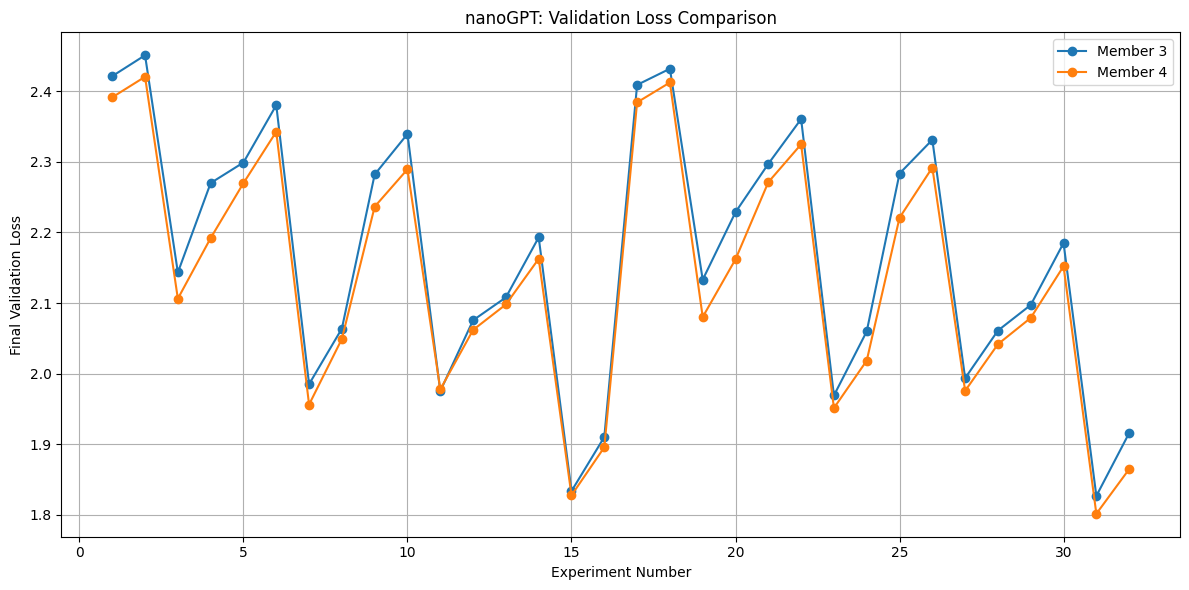

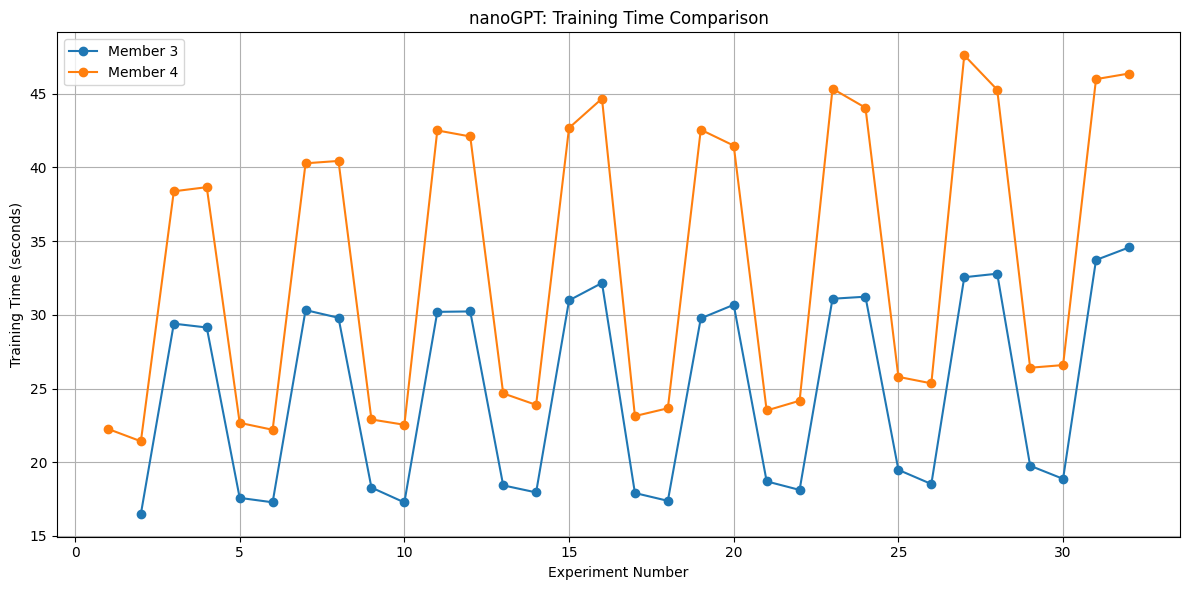


BEST MODEL CONFIGURATION
member                       4
experiment                  31
block_size                 128
n_layer                      6
n_head                       8
n_embd                     256
batch_size                  16
max_iters                 2000
dropout                    0.1
train_loss              1.6346
val_loss                1.8013
training_time_sec        45.99
status               completed


In [14]:

# Step 14: Load and visualize experiment results

import pandas as pd
import matplotlib.pyplot as plt
import os

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
results_file = os.path.join(base_dir, "experiment_results.csv")

df = pd.read_csv(results_file)
df = df[df["status"] == "completed"].copy()

print("Total completed experiments:", len(df))
display(df.head())

# Compare validation loss across experiments
plt.figure(figsize=(12, 6))

for member in [3, 4]:
    data = df[df["member"] == member].sort_values("experiment")
    plt.plot(
        data["experiment"],
        data["val_loss"],
        marker="o",
        label=f"Member {member}"
    )

plt.xlabel("Experiment Number")
plt.ylabel("Final Validation Loss")
plt.title("nanoGPT: Validation Loss Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(base_dir, "validation_loss_comparison.png"),
    dpi=300
)
plt.show()

# Compare training time
plt.figure(figsize=(12, 6))

for member in [3, 4]:
    data = df[df["member"] == member].sort_values("experiment")
    plt.plot(
        data["experiment"],
        data["training_time_sec"],
        marker="o",
        label=f"Member {member}"
    )

plt.xlabel("Experiment Number")
plt.ylabel("Training Time (seconds)")
plt.title("nanoGPT: Training Time Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(base_dir, "training_time_comparison.png"),
    dpi=300
)
plt.show()

# Find the best configuration
best = df.loc[df["val_loss"].idxmin()]

print("\nBEST MODEL CONFIGURATION")
print(best.to_string())


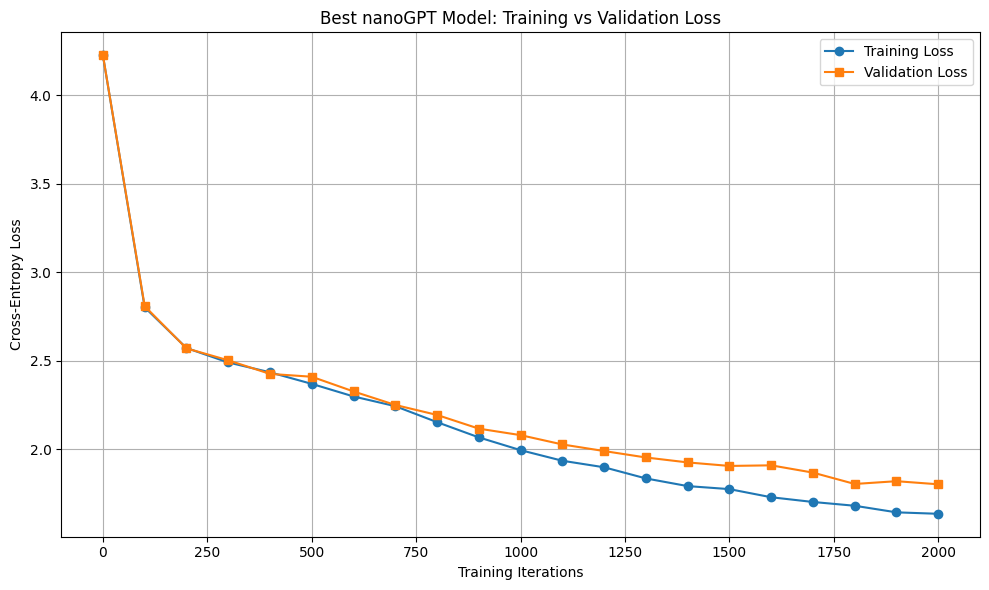

Graph saved to: /content/drive/MyDrive/nanoGPT_Experiments/best_model_loss_curves.png


In [15]:

# Step 15: Best model training and validation loss curves

import pandas as pd
import matplotlib.pyplot as plt
import os

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"

history_file = os.path.join(
    base_dir,
    "Member4",
    "Experiment31",
    "loss_history.csv"
)

history = pd.read_csv(history_file)

plt.figure(figsize=(10, 6))

plt.plot(
    history["step"],
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["step"],
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Training Iterations")
plt.ylabel("Cross-Entropy Loss")
plt.title("Best nanoGPT Model: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

save_path = os.path.join(
    base_dir, "best_model_loss_curves.png"
)

plt.savefig(save_path, dpi=300)
plt.show()

print("Graph saved to:", save_path)


In [16]:

# Step 16: Generate text using the best model

%cd /content/nanoGPT

!python sample.py \
    --init_from=resume \
    --out_dir=/content/drive/MyDrive/nanoGPT_Experiments/Member4/Experiment31 \
    --start="ROMEO:" \
    --num_samples=1 \
    --max_new_tokens=300 \
    --temperature=0.8 \
    --top_k=40 \
    --device=cuda \
    --dtype=float16 \
    --compile=False


/content/nanoGPT
Overriding: init_from = resume
Overriding: out_dir = /content/drive/MyDrive/nanoGPT_Experiments/Member4/Experiment31
Overriding: start = ROMEO:
Overriding: num_samples = 1
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 40
Overriding: device = cuda
Overriding: dtype = float16
Overriding: compile = False
number of parameters: 4.74M
Loading meta from data/shakespeare_char/meta.pkl...
ROMEO:
You be not dever, which yet the crew bube a was
Thrue my call and barthing put of her bardding
Have away, and none a wize our
You, proof is her to standing, and is entenger.

SICHNGS:
Why so do be none him trange, less do was.

KING EDWARD IV:

KING EDWARD IV:
MONENIUS:
The sight well my would that
---------------


In [17]:

# Step 17: Model parameter count and GPU memory usage

import torch
import os
from model import GPT, GPTConfig

checkpoint_path = (
    "/content/drive/MyDrive/nanoGPT_Experiments/"
    "Member4/Experiment31/ckpt.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

config = GPTConfig(**checkpoint["model_args"])
model = GPT(config)

state_dict = checkpoint["model"]

# Handle checkpoints saved from compiled models
unwanted_prefix = "_orig_mod."
for key in list(state_dict.keys()):
    if key.startswith(unwanted_prefix):
        state_dict[key[len(unwanted_prefix):]] = state_dict.pop(key)

model.load_state_dict(state_dict)
model = model.to("cuda")
model.eval()

total_params = sum(p.numel() for p in model.parameters())

torch.cuda.reset_peak_memory_stats()

x = torch.randint(
    0, config.vocab_size,
    (1, config.block_size),
    device="cuda"
)

with torch.no_grad():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        logits, loss = model(x)

peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)

print(f"Total parameters: {total_params:,}")
print(f"Parameters (millions): {total_params / 1e6:.2f}M")
print(f"Peak allocated GPU memory: {peak_memory:.2f} MB")


number of parameters: 4.74M
Total parameters: 4,771,328
Parameters (millions): 4.77M
Peak allocated GPU memory: 36.27 MB



n_layer
n_layer
4    2.166138
6    2.134703
Name: val_loss, dtype: float64


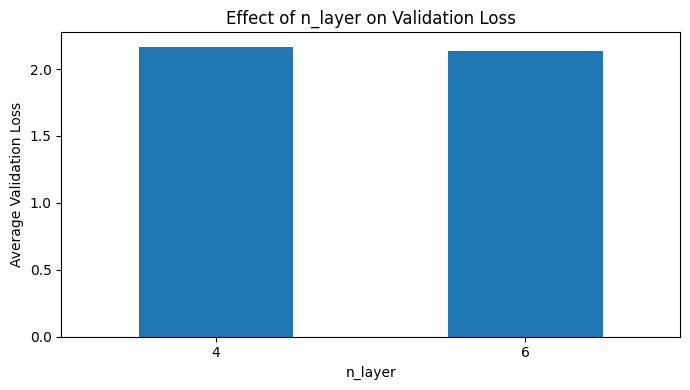


n_head
n_head
4    2.156566
8    2.144275
Name: val_loss, dtype: float64


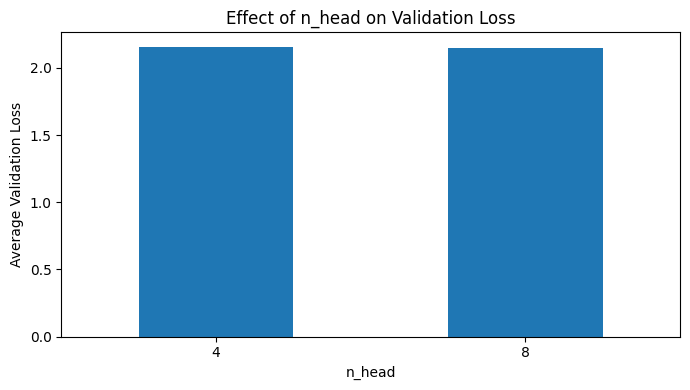


n_embd
n_embd
128    2.226203
256    2.074638
Name: val_loss, dtype: float64


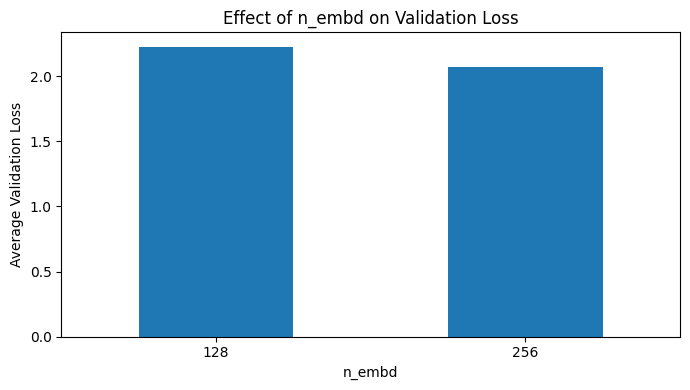


batch_size
batch_size
8     2.221166
16    2.079675
Name: val_loss, dtype: float64


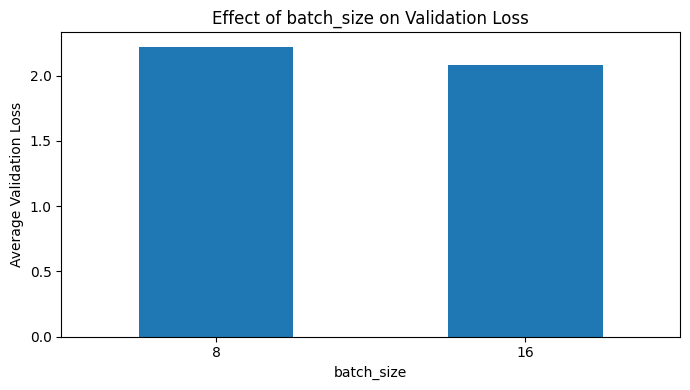


max_iters
max_iters
1000    2.288175
2000    2.012666
Name: val_loss, dtype: float64


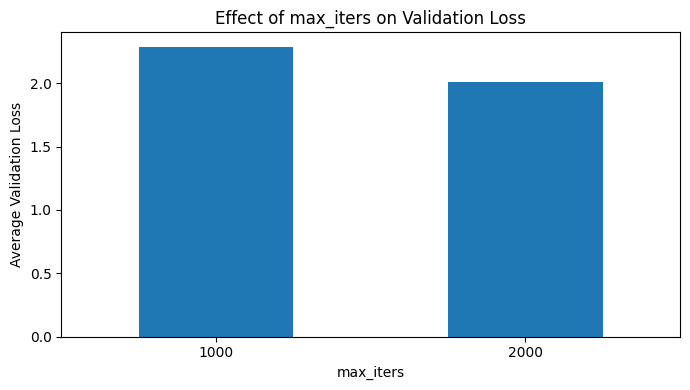


dropout
dropout
0.1    2.115162
0.2    2.185678
Name: val_loss, dtype: float64


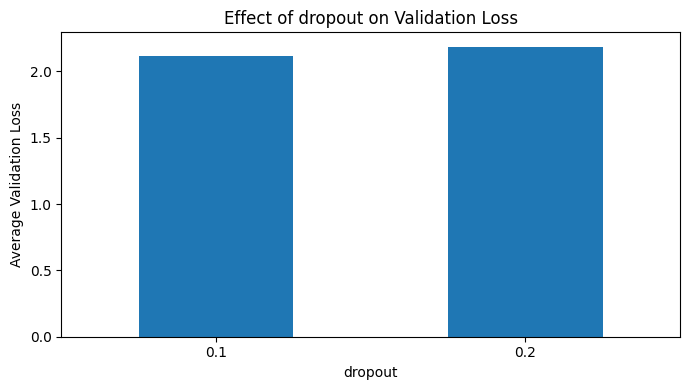


Hyperparameter analysis completed!


In [18]:

# Step 18: Hyperparameter impact analysis

import pandas as pd
import matplotlib.pyplot as plt
import os

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"

df = pd.read_csv(
    os.path.join(base_dir, "experiment_results.csv")
)

df = df[df["status"] == "completed"].copy()

parameters = [
    "n_layer",
    "n_head",
    "n_embd",
    "batch_size",
    "max_iters",
    "dropout"
]

summary = []

for parameter in parameters:
    grouped = df.groupby(parameter)["val_loss"].mean()

    print(f"\n{parameter}")
    print(grouped)

    for value, loss in grouped.items():
        summary.append({
            "Hyperparameter": parameter,
            "Value": value,
            "Average Validation Loss": loss
        })

    plt.figure(figsize=(7, 4))
    grouped.plot(kind="bar")

    plt.title(f"Effect of {parameter} on Validation Loss")
    plt.xlabel(parameter)
    plt.ylabel("Average Validation Loss")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        os.path.join(base_dir, f"effect_{parameter}.png"),
        dpi=300
    )
    plt.show()

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    os.path.join(base_dir, "hyperparameter_analysis.csv"),
    index=False
)

print("\nHyperparameter analysis completed!")


In [19]:

# Step 19: Final results summary

import pandas as pd
import os

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"

df = pd.read_csv(
    os.path.join(base_dir, "experiment_results.csv")
)

df = df[df["status"] == "completed"].copy()

# Verify all experiment combinations are unique
assert len(df) == 64, "Expected 64 completed experiments"
assert not df.duplicated(
    ["member", "experiment"]
).any(), "Duplicate experiments found"

print("MEMBER-WISE RESULTS")
summary = df.groupby("member").agg(
    experiments=("experiment", "count"),
    avg_train_loss=("train_loss", "mean"),
    avg_val_loss=("val_loss", "mean"),
    total_time_sec=("training_time_sec", "sum")
)

print(summary.round(4))

print("\nBEST CONFIGURATION")
best = df.loc[df["val_loss"].idxmin()]
print(best.to_string())

print("\nHYPERPARAMETER COMPARISON")
for parameter in [
    "n_layer", "n_head", "n_embd",
    "batch_size", "max_iters", "dropout"
]:
    print(f"\n{parameter}")
    print(
        df.groupby(parameter)["val_loss"]
        .mean().round(4)
    )

summary.to_csv(
    os.path.join(base_dir, "member_summary.csv")
)

df.sort_values(
    ["member", "experiment"]
).to_csv(
    os.path.join(base_dir, "final_64_experiments.csv"),
    index=False
)

print("\nFinal summary files saved successfully!")


MEMBER-WISE RESULTS
        experiments  avg_train_loss  avg_val_loss  total_time_sec
member                                                           
3                32          2.1067        2.1661          770.65
4                32          2.0584        2.1347         1069.55

BEST CONFIGURATION
member                       4
experiment                  31
block_size                 128
n_layer                      6
n_head                       8
n_embd                     256
batch_size                  16
max_iters                 2000
dropout                    0.1
train_loss              1.6346
val_loss                1.8013
training_time_sec        45.99
status               completed

HYPERPARAMETER COMPARISON

n_layer
n_layer
4    2.1661
6    2.1347
Name: val_loss, dtype: float64

n_head
n_head
4    2.1566
8    2.1443
Name: val_loss, dtype: float64

n_embd
n_embd
128    2.2262
256    2.0746
Name: val_loss, dtype: float64

batch_size
batch_size
8     2.2212
16    2.0797
N

In [20]:

# Step 20: Package results for teammates

import os
import zipfile

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
zip_path = "/content/drive/MyDrive/nanoGPT_Results_Members3_4.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file.endswith((".csv", ".png", ".log")):
                full_path = os.path.join(root, file)
                relative_path = os.path.relpath(
                    full_path, base_dir
                )
                zipf.write(full_path, relative_path)

print("Results ZIP created successfully!")
print("Saved to:", zip_path)


Results ZIP created successfully!
Saved to: /content/drive/MyDrive/nanoGPT_Results_Members3_4.zip


In [1]:

import os

zip_path = "/content/drive/MyDrive/nanoGPT_Results_Members3_4.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")
else:
    print("ZIP not found at the expected location.")


ZIP exists: False
ZIP not found at the expected location.


In [2]:

from google.colab import drive
import os

drive.mount("/content/drive")

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"

print("Experiment folder exists:", os.path.exists(base_dir))

if os.path.exists(base_dir):
    print("\nFiles and folders:")
    print(os.listdir(base_dir))

    results_file = os.path.join(
        base_dir, "experiment_results.csv"
    )
    print("\nResults CSV exists:", os.path.isfile(results_file))
else:
    print("Experiment folder not found.")


Mounted at /content/drive
Experiment folder exists: True

Files and folders:
['Member3', 'Member4', 'experiment_results.csv']

Results CSV exists: True


In [3]:

# Recreate nanoGPT results ZIP

import os
import zipfile
from google.colab import files

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
zip_path = "/content/nanoGPT_Results_Members3_4.zip"

file_count = 0

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(base_dir):
        for filename in filenames:
            if filename.endswith((".csv", ".png", ".log")):
                full_path = os.path.join(root, filename)
                relative_path = os.path.relpath(full_path, base_dir)

                zipf.write(full_path, relative_path)
                file_count += 1

print("ZIP created successfully!")
print("Files included:", file_count)
print("ZIP size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")

# Download ZIP to your computer
files.download(zip_path)


ZIP created successfully!
Files included: 99
ZIP size: 0.13 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

import pandas as pd
import os

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
results_file = os.path.join(base_dir, "experiment_results.csv")

df = pd.read_csv(results_file)

print("Total records:", len(df))
print("\nCompleted experiments by member:")
print(df[df["status"] == "completed"].groupby("member").size())

print("\nGraphs saved in Drive:")
print([f for f in os.listdir(base_dir) if f.endswith(".png")])


Total records: 50

Completed experiments by member:
member
3    32
4    18
dtype: int64

Graphs saved in Drive:
[]


In [5]:

import os

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
member4_dir = os.path.join(base_dir, "Member4")

print("MEMBER 4 CHECKPOINT STATUS\n")

for i in range(1, 33):
    exp_dir = os.path.join(member4_dir, f"Experiment{i}")

    checkpoint = os.path.join(exp_dir, "ckpt.pt")
    history = os.path.join(exp_dir, "loss_history.csv")
    log = os.path.join(exp_dir, "training.log")

    print(
        f"Experiment {i:02d}: "
        f"Checkpoint={os.path.isfile(checkpoint)}, "
        f"History={os.path.isfile(history)}, "
        f"Log={os.path.isfile(log)}"
    )


MEMBER 4 CHECKPOINT STATUS

Experiment 01: Checkpoint=True, History=True, Log=True
Experiment 02: Checkpoint=True, History=True, Log=True
Experiment 03: Checkpoint=True, History=True, Log=True
Experiment 04: Checkpoint=True, History=True, Log=True
Experiment 05: Checkpoint=True, History=True, Log=True
Experiment 06: Checkpoint=True, History=True, Log=True
Experiment 07: Checkpoint=True, History=True, Log=True
Experiment 08: Checkpoint=True, History=True, Log=True
Experiment 09: Checkpoint=True, History=True, Log=True
Experiment 10: Checkpoint=True, History=True, Log=True
Experiment 11: Checkpoint=True, History=True, Log=True
Experiment 12: Checkpoint=True, History=True, Log=True
Experiment 13: Checkpoint=True, History=True, Log=True
Experiment 14: Checkpoint=True, History=True, Log=True
Experiment 15: Checkpoint=False, History=True, Log=True
Experiment 16: Checkpoint=False, History=True, Log=True
Experiment 17: Checkpoint=True, History=True, Log=True
Experiment 18: Checkpoint=True, His

In [6]:

import os
import pandas as pd

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
results_file = os.path.join(base_dir, "experiment_results.csv")

df = pd.read_csv(results_file)

member4 = df[df["member"] == 4]

saved = set(member4["experiment"].astype(int))
expected = set(range(1, 33))

missing = sorted(expected - saved)

print("Member 4 saved experiments:", len(saved))
print("Missing experiment numbers:", missing)

print("\nMember 4 available results:")
print(member4[[
    "experiment", "train_loss", "val_loss"
]].to_string(index=False))


Member 4 saved experiments: 18
Missing experiment numbers: [19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]

Member 4 available results:
 experiment  train_loss  val_loss
          1      2.3716    2.3916
          2      2.4060    2.4207
          3      2.0246    2.1062
          4      2.1374    2.1921
          5      2.2631    2.2700
          6      2.3394    2.3428
          7      1.8259    1.9561
          8      1.9451    2.0491
          9      2.2123    2.2366
         10      2.2752    2.2896
         11      1.8217    1.9776
         12      1.9274    2.0619
         13      2.0070    2.0980
         14      2.1022    2.1627
         15      1.6618    1.8275
         16      1.7413    1.8956
         17      2.3645    2.3844
         18      2.3992    2.4126


In [7]:

from google.colab import files
import pandas as pd
import os

# Upload recovered experiment results
uploaded = files.upload()

# Read uploaded CSV
filename = next(iter(uploaded))
recovered_df = pd.read_csv(filename)

print("File uploaded successfully!")
print("Filename:", filename)
print("Recovered experiments:", len(recovered_df))

# Display recovered results
display(recovered_df)


Saving nanoGPT_Member4_Recovered_Experiments_19_32 (1).csv to nanoGPT_Member4_Recovered_Experiments_19_32 (1).csv
File uploaded successfully!
Filename: nanoGPT_Member4_Recovered_Experiments_19_32 (1).csv
Recovered experiments: 14


,member,experiment,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,training_time_sec,status
0,4,19,128,6,8,128,8,2000,0.1,1.9962,2.0802,42.56,completed
1,4,20,128,6,8,128,8,2000,0.2,2.1087,2.1620,41.48,completed
2,4,21,128,6,8,128,16,1000,0.1,2.2612,2.2713,23.51,completed
3,4,22,128,6,8,128,16,1000,0.2,2.3212,2.3250,24.17,completed
4,4,23,128,6,8,128,16,2000,0.1,1.8078,1.9512,45.34,completed
5,4,24,128,6,8,128,16,2000,0.2,1.9144,2.0184,44.05,completed
6,4,25,128,6,8,256,8,1000,0.1,2.1973,2.2209,25.79,completed
7,4,26,128,6,8,256,8,1000,0.2,2.2774,2.2920,25.35,completed
8,4,27,128,6,8,256,8,2000,0.1,1.8148,1.9756,47.61,completed
9,4,28,128,6,8,256,8,2000,0.2,1.9112,2.0417,45.27,completed


In [8]:

import pandas as pd
import os
import shutil

# Existing experiment results
base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
results_file = os.path.join(base_dir, "experiment_results.csv")

# Load original results
original_df = pd.read_csv(results_file)

# recovered_df is already loaded from the previous cell
print("Original records:", len(original_df))
print("Recovered records:", len(recovered_df))

# Ensure columns match
assert set(original_df.columns) == set(recovered_df.columns), \
    "Column mismatch! Check CSV columns before merging."

# Match the original column order
recovered_df = recovered_df[original_df.columns]

# Combine both datasets
combined_df = pd.concat(
    [original_df, recovered_df],
    ignore_index=True
)

# Check for duplicate experiments
duplicates = combined_df.duplicated(
    subset=["member", "experiment"]
)

assert not duplicates.any(), "Duplicate experiments found!"

# Verify all experiments are present
for member in [3, 4]:
    experiments = set(
        combined_df.loc[
            combined_df["member"] == member, "experiment"
        ].astype(int)
    )
    assert experiments == set(range(1, 33)), \
        f"Missing experiments for Member {member}"

assert len(combined_df) == 64, "Expected 64 records!"

# Back up original CSV before replacing
backup_file = os.path.join(
    base_dir, "experiment_results_backup_50.csv"
)
shutil.copy2(results_file, backup_file)

# Save completed CSV
combined_df = combined_df.sort_values(
    ["member", "experiment"]
)

combined_df.to_csv(results_file, index=False)

print("\nSUCCESS! All 64 experiments restored.")
print("\nCompleted experiments by member:")
print(combined_df.groupby("member").size())
print("\nSaved to:", results_file)
print("Backup saved to:", backup_file)


Original records: 50
Recovered records: 14

SUCCESS! All 64 experiments restored.

Completed experiments by member:
member
3    32
4    32
dtype: int64

Saved to: /content/drive/MyDrive/nanoGPT_Experiments/experiment_results.csv
Backup saved to: /content/drive/MyDrive/nanoGPT_Experiments/experiment_results_backup_50.csv


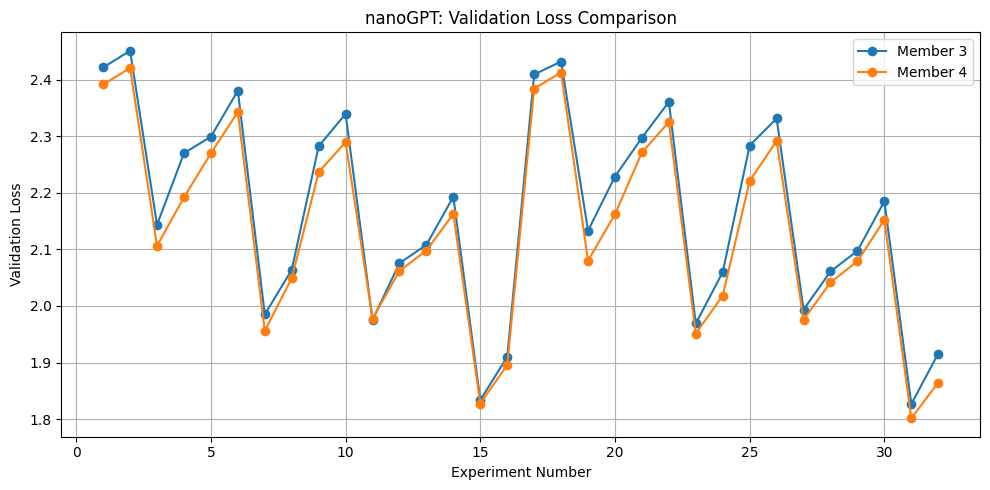

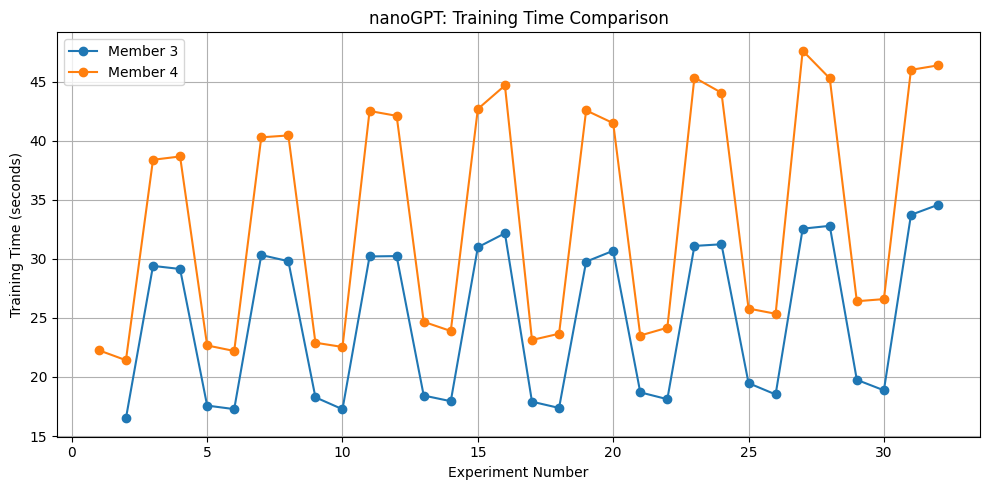

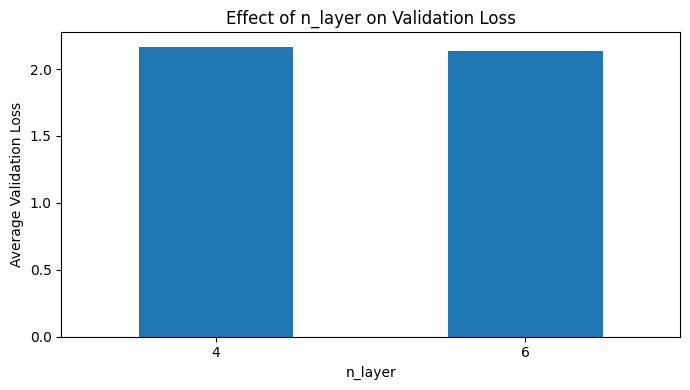

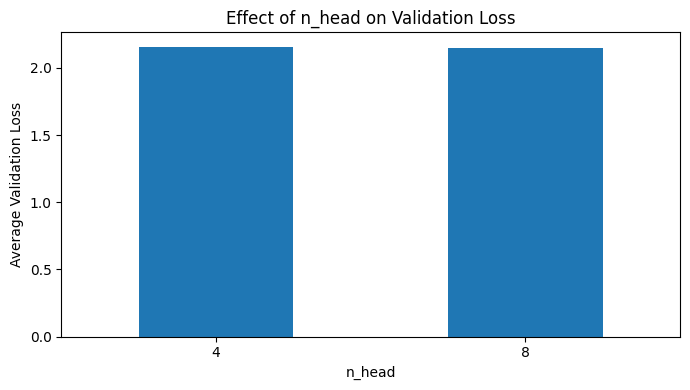

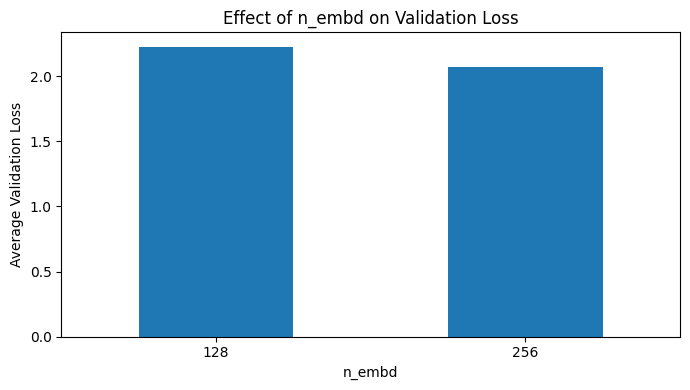

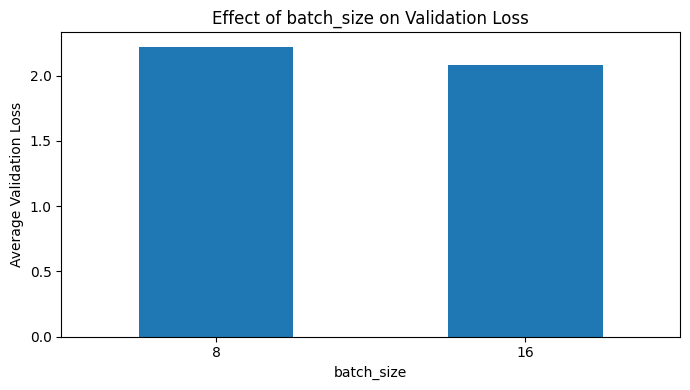

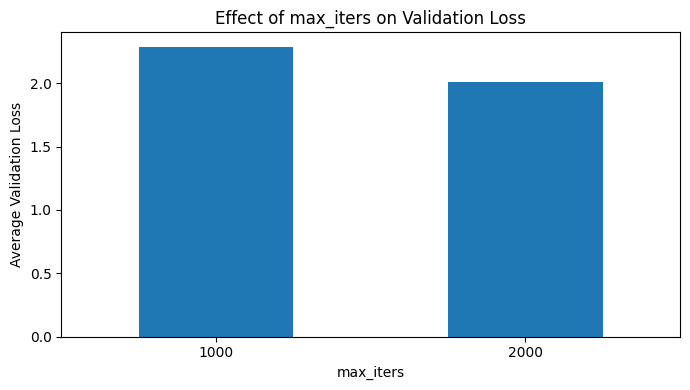

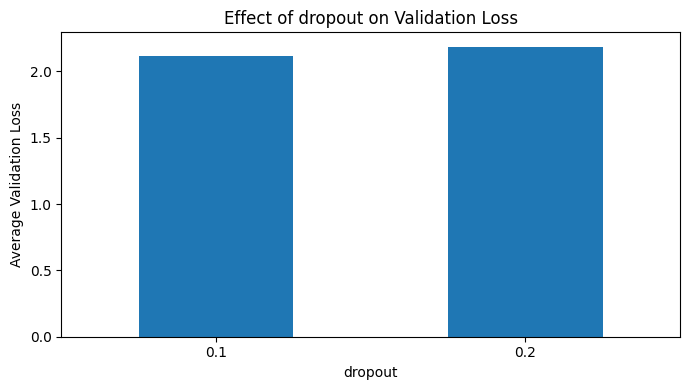

All graphs saved to: /content/drive/MyDrive/nanoGPT_Experiments/graphs


In [9]:

import os
import pandas as pd
import matplotlib.pyplot as plt

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
df = pd.read_csv(os.path.join(base_dir, "experiment_results.csv"))

graphs_dir = os.path.join(base_dir, "graphs")
os.makedirs(graphs_dir, exist_ok=True)

# Graph 1: Validation loss comparison
plt.figure(figsize=(10, 5))

for member in [3, 4]:
    subset = df[df["member"] == member].sort_values("experiment")
    plt.plot(
        subset["experiment"],
        subset["val_loss"],
        marker="o",
        label=f"Member {member}"
    )

plt.title("nanoGPT: Validation Loss Comparison")
plt.xlabel("Experiment Number")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs_dir, "validation_loss_comparison.png"))
plt.show()

# Graph 2: Training time comparison
plt.figure(figsize=(10, 5))

for member in [3, 4]:
    subset = df[df["member"] == member].sort_values("experiment")
    plt.plot(
        subset["experiment"],
        pd.to_numeric(subset["training_time_sec"], errors="coerce"),
        marker="o",
        label=f"Member {member}"
    )

plt.title("nanoGPT: Training Time Comparison")
plt.xlabel("Experiment Number")
plt.ylabel("Training Time (seconds)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(graphs_dir, "training_time_comparison.png"))
plt.show()

# Graph 3: Hyperparameter impact
parameters = [
    "n_layer", "n_head", "n_embd",
    "batch_size", "max_iters", "dropout"
]

for param in parameters:
    averages = df.groupby(param)["val_loss"].mean()

    plt.figure(figsize=(7, 4))
    averages.plot(kind="bar")
    plt.title(f"Effect of {param} on Validation Loss")
    plt.xlabel(param)
    plt.ylabel("Average Validation Loss")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(os.path.join(graphs_dir, f"effect_{param}.png"))
    plt.show()

print("All graphs saved to:", graphs_dir)


In [10]:

import os
import zipfile
from google.colab import files

base_dir = "/content/drive/MyDrive/nanoGPT_Experiments"
zip_path = "/content/nanoGPT_Final_Results_Members3_4.zip"

file_count = 0

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(base_dir):
        for filename in filenames:
            if filename.endswith((".csv", ".png", ".log")):
                full_path = os.path.join(root, filename)
                relative_path = os.path.relpath(full_path, base_dir)

                zipf.write(full_path, relative_path)
                file_count += 1

# Verify ZIP integrity
with zipfile.ZipFile(zip_path, "r") as zipf:
    bad_file = zipf.testzip()
    assert bad_file is None, f"Corrupted file: {bad_file}"

print("Final ZIP created successfully!")
print("Files included:", file_count)
print("ZIP size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")

# Download to computer
files.download(zip_path)


Final ZIP created successfully!
Files included: 108
ZIP size: 0.36 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>